# DS201 · LAB 3: MẠNG NEURAL HỒI QUY (RNN, LSTM, GRU VÀ BiLSTM)

**Bản thực hành sinh viên**

Phần A–B dùng mạng nhỏ trên toàn bộ dữ liệu train/dev để quan sát luồng xử lý trong giờ học. Khi làm Phần C, sửa `cfg` ở ô cấu hình theo yêu cầu của đề (5 lớp, hidden_size=256) rồi Restart Kernel/Run All.

In [1]:
pip install -q --use-pep517 torch numpy pandas matplotlib scikit-learn seqeval

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## Phần A. Chuẩn bị trước buổi học

### Kiểm tra môi trường và chọn cấu hình

Dùng lại vòng lặp PyTorch của Lab 1–2. `cfg` là cấu hình duy nhất của notebook: giá trị mặc định là mạng nhỏ để chạy kịp trong giờ học. Khi làm Phần C, đổi `cfg` theo cấu hình chung của đề rồi Restart Kernel và Run All.

In [2]:
import copy, hashlib, json, random, time, urllib.request
from collections import Counter
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.nn.utils.rnn import (
    pad_sequence, pack_padded_sequence, pad_packed_sequence,
)
from torch.utils.data import DataLoader
from sklearn.metrics import (
    classification_report, f1_score, accuracy_score,
    confusion_matrix, ConfusionMatrixDisplay,
)
from seqeval.metrics import f1_score as entity_f1
from seqeval.metrics import classification_report as entity_report
from seqeval.scheme import IOB2
import matplotlib.pyplot as plt

def seed_all(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_all()
torch.set_num_threads(min(4, torch.get_num_threads()))
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# Phần C: emb=300, hidden=256, layers=5, epochs=10, ner_epochs=10
cfg = dict(emb=64, hidden=64, layers=1, epochs=2, ner_epochs=3,
           batch=32, dropout=0.3, lr=1e-3)
base = Path.cwd()
LAB = base / "Lab3" if (base / "Lab3").is_dir() else base
DATA = LAB / "data"
ART = LAB / "artifacts"
ART.mkdir(parents=True, exist_ok=True)
print("PyTorch:", torch.__version__, "| Thiết bị:", device)
print("Cấu hình:", cfg)

PyTorch: 2.12.1+cpu | Thiết bị: cpu
Cấu hình: {'emb': 64, 'hidden': 64, 'layers': 1, 'epochs': 2, 'ner_epochs': 3, 'batch': 32, 'dropout': 0.3, 'lr': 0.001}


### Tải dữ liệu và xác nhận đúng phiên bản

Mỗi người tải trực tiếp từ nguồn của bộ dữ liệu. Nếu đã tải trước giờ học, chương trình kiểm tra checksum rồi dùng lại tệp. Giữ thư mục data trên máy cá nhân; khi nộp GitHub chỉ ghi nguồn tải và cách chạy.

PhoNER cho phép sử dụng cho giáo dục/nghiên cứu và yêu cầu không phân phối lại dữ liệu. Tải từ kho VinAI; không đính kèm dữ liệu trong repo nộp bài.

In [3]:
# Tải một lần; không đọc nội dung test để chọn mô hình.
DATA_FILES = [('uit-vsfc/UIT-VSFC-train.json', 'https://drive.google.com/uc?export=download&id=1eJdEStCQBf3GtbOIQfIR2iS-Wb3nlfJX', 'e41e65672f2ade65ee8d2d394659a2bfeabbce987f0d2ad9e19998068a78fc1e'), ('uit-vsfc/UIT-VSFC-dev.json', 'https://drive.google.com/uc?export=download&id=1UWbzHFeUPu4AuofOEy0Fo0SFotVZHzUe', 'ab781a38209c17e640e077f83d82ecb9ea4f3469e63fc6ec2a232b0da6fbe823'), ('uit-vsfc/UIT-VSFC-test.json', 'https://drive.google.com/uc?export=download&id=1g4imdabNbswIu91K6zKFGalkjDBBqaQq', '14a6c5697907084086551a17c76e908dad88f2dc3b8be720c9880c8fc1212aa6'), ('phoner/train_syllable.json', 'https://raw.githubusercontent.com/VinAIResearch/PhoNER_COVID19/main/data/syllable/train_syllable.json', 'fb4097f6ac956a03e484319898db0dafc7283c135cd7888f803ad26a5a253419'), ('phoner/dev_syllable.json', 'https://raw.githubusercontent.com/VinAIResearch/PhoNER_COVID19/main/data/syllable/dev_syllable.json', 'c74393fb5d1547d51ddda175830892ca62a7efa2d93291b21a35cb21bfee612e'), ('phoner/test_syllable.json', 'https://raw.githubusercontent.com/VinAIResearch/PhoNER_COVID19/main/data/syllable/test_syllable.json', '4b677028d6db5e1dab74d727d88b719454da60cfeaba681d9ee401fc83b04c77')]
for rel, url, expected in DATA_FILES:
    path = DATA / rel
    path.parent.mkdir(parents=True, exist_ok=True)
    if not path.exists():
        with urllib.request.urlopen(url, timeout=90) as response:
            content = response.read()
        if hashlib.sha256(content).hexdigest() != expected:
            raise ValueError("Nguồn tải đã đổi hoặc trả về HTML: " + rel)
        path.write_bytes(content)
    actual = hashlib.sha256(path.read_bytes()).hexdigest()
    if actual != expected:
        raise ValueError("Checksum không khớp: " + rel)
print("Đã xác nhận 6/6 tệp dữ liệu bằng SHA-256.")

Đã xác nhận 6/6 tệp dữ liệu bằng SHA-256.


### Đọc JSON, JSON Lines và kiểm tra nhãn

UIT-VSFC có hai nhiệm vụ. Lab này chỉ dùng sentiment với ba nhãn negative, neutral, positive; topic không phải đầu vào. PhoNER bản syllable đã có token và nhãn tương ứng, vì vậy không tách từ lại.

In [4]:
LABELS = ["negative", "neutral", "positive"]
label_to_id = {name: i for i, name in enumerate(LABELS)}
vsfc, ner = {}, {}
for split in ["train", "dev", "test"]:
    path = DATA / "uit-vsfc" / f"UIT-VSFC-{split}.json"
    vsfc[split] = json.loads(path.read_text(encoding="utf-8-sig"))
    assert all(r["sentiment"] in LABELS for r in vsfc[split])
    path = DATA / "phoner" / f"{split}_syllable.json"
    ner[split] = [json.loads(line) for line in
                  path.read_text(encoding="utf-8-sig").splitlines()
                  if line.strip()]
    assert all(len(r["words"]) == len(r["tags"]) > 0
               for r in ner[split])
    print(split, "| UIT-VSFC:", len(vsfc[split]),
          "| PhoNER:", len(ner[split]))
counts = Counter(r["sentiment"] for r in vsfc["train"])
print("Sentiment train:", {k: counts[k] for k in LABELS})
print("Kiểm tra token/nhãn PhoNER: PASS")

train | UIT-VSFC: 11426 | PhoNER: 5027
dev | UIT-VSFC: 1583 | PhoNER: 2000
test | UIT-VSFC: 3166 | PhoNER: 3000
Sentiment train: {'negative': 5325, 'neutral': 458, 'positive': 5643}
Kiểm tra token/nhãn PhoNER: PASS


### Tự kiểm tra trước khi đến lớp

Đối chiếu số câu và tên nhãn với tài liệu. Phần test chỉ được kiểm tra cấu trúc ở bước chuẩn bị; lựa chọn mô hình và siêu tham số luôn dựa trên dev.

In [5]:
assert [len(vsfc[s]) for s in vsfc] == [11426, 1583, 3166]
assert [len(ner[s]) for s in ner] == [5027, 2000, 3000]
assert set(counts) == set(LABELS)
print("3/3 kiểm tra chuẩn bị: PASS")

3/3 kiểm tra chuẩn bị: PASS


## B.1. Từ trạng thái ẩn đến RNN nhiều lớp

### Tính trạng thái ẩn qua ba bước thời gian

Đề bài: tính h_t = tanh(0.5 x_t + 0.8 h_(t−1)) với x = [1, 1, 1] và h_0 = 0. Cùng một bộ trọng số được dùng lại ở mọi bước, nên độ dài chuỗi không quyết định số tham số.

In [6]:
h = torch.tensor(0.0)
for t, x_t in enumerate([1.0, 1.0, 1.0], start=1):
    h = torch.tanh(0.5 * x_t + 0.8 * h)
    print(f"h_{t} = {h.item():.6f}")
print(f"0.5**50 = {0.5**50:.3e}")

h_1 = 0.462117
h_2 = 0.701218
h_3 = 0.786037
0.5**50 = 8.882e-16


### Đối chiếu output, h_n và c_n

Với batch_first=True, đầu vào có shape [B, L, E]. output chứa trạng thái tại từng vị trí của lớp trên cùng; h_n chứa trạng thái cuối của từng lớp và từng chiều. LSTM còn trả về c_n, còn RNN và GRU chỉ trả về h_n.

In [7]:
seed_all()
toy = torch.randn(3, 5, 8)
for name, cls in [("RNN", nn.RNN), ("GRU", nn.GRU),
                  ("LSTM", nn.LSTM)]:
    layer = cls(8, 16, num_layers=2, batch_first=True)
    output, state = layer(toy)
    hidden = state[0] if name == "LSTM" else state
    print(name, "output:", tuple(output.shape),
          "h_n:", tuple(hidden.shape),
          "params:", sum(p.numel() for p in layer.parameters()))
bi = nn.LSTM(8, 16, num_layers=2,
             bidirectional=True, batch_first=True)
output, (h_n, c_n) = bi(toy)
print("BiLSTM:", tuple(output.shape), tuple(h_n.shape),
      tuple(c_n.shape))

RNN output: (3, 5, 16) h_n: (2, 3, 16) params: 960
GRU output: (3, 5, 16) h_n: (2, 3, 16) params: 2880
LSTM output: (3, 5, 16) h_n: (2, 3, 16) params: 3840
BiLSTM: (3, 5, 32) (4, 3, 16) (4, 3, 16)


## B.2. Từ văn bản đến batch embedding

### Xây từ điển từ tập train

Dùng phép tách theo khoảng trắng trên văn bản UIT-VSFC đã có trong tệp, giữ nguyên dấu gạch nối từ nếu có. Đây là quy ước đơn giản cho lab, không phải tuyên bố rằng mỗi âm tiết là một từ tiếng Việt. PhoNER giữ nguyên danh sách words, kể cả dấu câu và chữ hoa.

- TODO 1: Dùng từ điển; từ chưa thấy chuyển thành UNK.

In [29]:
PAD, UNK = 0, 1
def tokenize(text):
    return text.lower().split()

def build_vocab(sequences, min_freq=2):
    freq = Counter(t for tokens in sequences for t in tokens)
    tokens = sorted(t for t, n in freq.items() if n >= min_freq)
    return {"<pad>": PAD, "<unk>": UNK,
            **{t: i + 2 for i, t in enumerate(tokens)}}

vocab = build_vocab(tokenize(r["sentence"])
                    for r in vsfc["train"])
def encode(tokens, mapping):
    # Câu rỗng vẫn cần một bước để packing nhận length > 0.
    return [mapping.get(t, UNK) for t in tokens] or [UNK]

example = tokenize("giảng viên dạy rất hay")
print("Token minh họa:", example)
print("Chỉ số:", encode(example, vocab))
print("Kích thước từ điển train:", len(vocab))
assert vocab["<pad>"] == 0 and vocab["<unk>"] == 1

Token minh họa: ['giảng', 'viên', 'dạy', 'rất', 'hay']
Chỉ số: [394, 1313, 337, 978, 436]
Kích thước từ điển train: 1535


### Tạo batch có độ dài khác nhau

collate_fn trả về cả ids và lengths. Padding chỉ nhằm ghép các câu thành tensor, không phải nội dung của câu. Độ dài thật phải được giữ lại trước khi thêm padding.

In [30]:
def cls_rows(rows):
    return [(encode(tokenize(r["sentence"]), vocab),
             label_to_id[r["sentiment"]]) for r in rows]

def collate_cls(rows):
    ids = [torch.tensor(x, dtype=torch.long) for x, _ in rows]
    lengths = torch.tensor([len(x) for x in ids])
    x = pad_sequence(ids, batch_first=True, padding_value=PAD)
    y = torch.tensor([label for _, label in rows])
    return x, lengths, y

demo_rows = [(encode(tokenize(t), vocab), y) for t, y in [
    ("dạy hay", 2), ("nội dung còn khó hiểu", 0),
    ("bình thường", 1)]]
x, lengths, y = collate_cls(demo_rows)
print("ids shape:", tuple(x.shape), "| lengths:", lengths.tolist())
print("nhãn:", y.tolist())
emb = nn.Embedding(len(vocab), 8, padding_idx=PAD)
print("embedding shape:", tuple(emb(x).shape))
print("Vector PAD bằng 0:", bool(torch.all(emb.weight[PAD] == 0)))

ids shape: (3, 5) | lengths: [2, 5, 2]
nhãn: [2, 0, 1]
embedding shape: (3, 5, 8)
Vector PAD bằng 0: True


## B.3. Baseline và macro-F1 cho phân loại cảm xúc

### Chạy hai baseline trên UIT-VSFC

Đề bài: đo macro-F1 trên dev trước khi huấn luyện RNN. TF-IDF chỉ fit trên train; cả vectorizer và bộ phân loại đều không học từ dev/test. Nhãn neutral ít mẫu nên cần xem F1 từng lớp, thay vì chỉ nhìn accuracy.

In [31]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

train_text = [r["sentence"] for r in vsfc["train"]]
dev_text = [r["sentence"] for r in vsfc["dev"]]
train_y = [label_to_id[r["sentiment"]] for r in vsfc["train"]]
dev_y = [label_to_id[r["sentiment"]] for r in vsfc["dev"]]
majority = Counter(train_y).most_common(1)[0][0]
baseline = make_pipeline(
    TfidfVectorizer(ngram_range=(1, 2), min_df=2,
                    token_pattern=r"(?u)\b\w+\b"),
    LogisticRegression(max_iter=1000, random_state=42),
)
baseline.fit(train_text, train_y)
base_pred = baseline.predict(dev_text)
print("Majority dev macro-F1:", round(f1_score(
    dev_y, [majority] * len(dev_y), labels=[0, 1, 2],
    average="macro", zero_division=0), 4))
print("TF-IDF dev macro-F1:", round(f1_score(
    dev_y, base_pred, labels=[0, 1, 2],
    average="macro", zero_division=0), 4))
print(classification_report(dev_y, base_pred, labels=[0, 1, 2],
                            target_names=LABELS,
                            digits=4, zero_division=0))

Majority dev macro-F1: 0.2247
TF-IDF dev macro-F1: 0.6894
              precision    recall  f1-score   support

    negative     0.8855    0.9546    0.9188       705
     neutral     0.8182    0.1233    0.2143        73
    positive     0.9310    0.9391    0.9351       805

    accuracy                         0.9084      1583
   macro avg     0.8782    0.6723    0.6894      1583
weighted avg     0.9056    0.9084    0.8946      1583



## B.4. LSTM: packing, huấn luyện và đánh giá

### Cài mô hình phân loại dùng packing

Embedding chuyển ids thành vector. pack_padded_sequence loại bước đệm khỏi phép hồi quy; lengths đặt trên CPU. Mô hình một chiều lấy h_n[-1]; mô hình hai chiều ghép h_n[-2] và h_n[-1]. Lớp cuối trả logits trực tiếp cho CrossEntropyLoss.

- TODO 2: Truyền độ dài thật cho packing.

In [32]:
class TextClassifier(nn.Module):
    def __init__(self, vocab_size, kind="LSTM", emb=64,
                 hidden=64, layers=1, dropout=0.3,
                 bidirectional=False):
        super().__init__()
        self.kind = kind
        self.bidirectional = bidirectional
        self.emb = nn.Embedding(vocab_size, emb, padding_idx=PAD)
        cls = {"RNN": nn.RNN, "LSTM": nn.LSTM, "GRU": nn.GRU}[kind]
        self.rnn = cls(emb, hidden, layers, batch_first=True,
                       bidirectional=bidirectional,
                       dropout=dropout if layers > 1 else 0.0)
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden * (2 if bidirectional else 1), 3)

    def forward(self, ids, lengths):
        embedded = self.emb(ids)
        packed = pack_padded_sequence(
            embedded, lengths.cpu(), batch_first=True,
            enforce_sorted=False,
        )
        _, state = self.rnn(packed)
        h = state[0] if self.kind == "LSTM" else state
        vec = torch.cat([h[-2], h[-1]], dim=1) \
              if self.bidirectional else h[-1]
        return self.fc(self.drop(vec))

model_args = {k: cfg[k] for k in
              ["emb", "hidden", "layers", "dropout"]}
seed_all()
lstm = TextClassifier(len(vocab), **model_args).to(device)
print("logits shape:", tuple(lstm(x.to(device), lengths).shape))
print("Số tham số:", sum(p.numel() for p in lstm.parameters()))


logits shape: (3, 3)
Số tham số: 131715


### Kiểm tra cùng câu với hai độ dài đệm

Đề bài: đệm cùng một câu đến 8 và 64 vị trí rồi so logits trong eval mode. packing phải làm kết quả gần bằng nhau theo sai số số thực. padding_idx=0 chỉ ngăn học embedding PAD, bản thân nó không ngăn RNN cập nhật trạng thái ở các bước đệm.

In [33]:
sentence_ids = encode(tokenize("giảng viên dạy hay"), vocab)
def padded(length):
    return torch.tensor([sentence_ids +
                         [PAD] * (length - len(sentence_ids))],
                         device=device)

lens = torch.tensor([len(sentence_ids)])
lstm.eval()
with torch.no_grad():
    a = lstm(padded(8), lens)
    b = lstm(padded(64), lens)
    raw_a, _ = lstm.rnn(lstm.emb(padded(8)))
    raw_b, _ = lstm.rnn(lstm.emb(padded(64)))
torch.testing.assert_close(a, b, atol=1e-6, rtol=1e-5)
print("Packing, đệm 8 và 64: PASS")
print("Sai khác khi dùng output[:, -1] không packing:",
      round((raw_a[:, -1] - raw_b[:, -1]).abs().max().item(), 6))

Packing, đệm 8 và 64: PASS
Sai khác khi dùng output[:, -1] không packing: 0.045818


### Chuẩn bị DataLoader

Dùng toàn bộ train và dev; từ điển chỉ xây từ train. Mọi mô hình phân loại dùng cùng dữ liệu và cùng thứ tự batch khởi tạo từ seed 42.

In [36]:
cls_train = cls_rows(vsfc["train"])
cls_dev = cls_rows(vsfc["dev"])
def cls_loader(rows, shuffle=False):
    return DataLoader(rows, batch_size=cfg["batch"],
                      shuffle=shuffle, collate_fn=collate_cls,
                      generator=torch.Generator().manual_seed(42))

dev_loader = cls_loader(cls_dev)
print("Số câu train/dev:",
      len(cls_train), len(cls_dev))

Số câu train/dev: 11426 1583


### Viết vòng lặp huấn luyện và chọn checkpoint

Mỗi batch: zero_grad → forward → loss → backward → clip gradient → step. Loss mỗi epoch được lấy trung bình có trọng số theo số mẫu. eval kết hợp no_grad để đánh giá; chỉ trạng thái có macro-F1 tốt nhất trên dev được giữ lại.

- TODO 3: Chặn chuẩn gradient sau backward, trước step.

In [37]:
def evaluate_cls(model, loader):
    model.eval()
    true, pred = [], []
    with torch.no_grad():
        for ids, lengths, labels in loader:
            logits = model(ids.to(device), lengths)
            true.extend(labels.tolist())
            pred.extend(logits.argmax(-1).cpu().tolist())
    score = f1_score(true, pred, labels=[0, 1, 2],
                     average="macro", zero_division=0)
    return score, true, pred

def fit_cls(model, name):
    optimizer = torch.optim.Adam(model.parameters(), lr=cfg["lr"])
    criterion = nn.CrossEntropyLoss()
    best, best_state, history = -1.0, None, []
    loader = cls_loader(cls_train, shuffle=True)
    for epoch in range(1, cfg["epochs"] + 1):
        start = time.perf_counter()
        model.train()
        total_loss, total = 0.0, 0
        for ids, lengths, labels in loader:
            ids, labels = ids.to(device), labels.to(device)
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(ids, lengths), labels)
            loss.backward()
            pass  # TODO: clip gradient
            optimizer.step()
            total_loss += loss.item() * labels.numel()
            total += labels.numel()
        seconds = time.perf_counter() - start
        score, _, _ = evaluate_cls(model, dev_loader)
        history.append(dict(epoch=epoch, loss=total_loss / total,
                            dev_f1=score, seconds=seconds))
        if score > best:
            best, best_state = score, copy.deepcopy(model.state_dict())
        print(f"{name} epoch {epoch}: loss={total_loss/total:.4f} "
              f"dev_macro_F1={score:.4f}")
    model.load_state_dict(best_state)
    model.eval()
    torch.save(best_state, ART / f"{name}.pt")
    return history
print("Đã định nghĩa fit_cls và evaluate_cls.")

Đã định nghĩa fit_cls và evaluate_cls.


### Huấn luyện LSTM và đọc F1 từng lớp

Lần chạy tại lớp kiểm chứng pipeline với mạng nhỏ và ít epoch, không đặt ngưỡng F1 phải đạt. Baseline ở B.3 dùng cùng train/dev nên có thể đặt cạnh nhau, nhưng mạng nhỏ chưa đại diện cho cấu hình 5 lớp của Phần C.

In [38]:
seed_all()
lstm = TextClassifier(len(vocab), kind="LSTM", **model_args).to(device)
lstm_history = fit_cls(lstm, "lstm")
lstm_score, y_true, y_pred = evaluate_cls(lstm, dev_loader)
print(classification_report(y_true, y_pred, labels=[0, 1, 2],
                            target_names=LABELS,
                            digits=4, zero_division=0))

lstm epoch 1: loss=0.5180 dev_macro_F1=0.5948
lstm epoch 2: loss=0.3333 dev_macro_F1=0.6151
              precision    recall  f1-score   support

    negative     0.8487    0.9546    0.8985       705
     neutral     1.0000    0.0137    0.0270        73
    positive     0.9290    0.9106    0.9197       805

    accuracy                         0.8888      1583
   macro avg     0.9259    0.6263    0.6151      1583
weighted avg     0.8965    0.8888    0.8691      1583



## B.5. GRU và so sánh có kiểm soát

### Huấn luyện GRU với cùng cấu hình

GRU trả thẳng h_n, còn LSTM trả (h_n, c_n). Giữ nguyên cách chia dữ liệu, embedding, hidden size, số lớp, batch và learning rate. Số tham số và thời gian là hai yếu tố cần đọc cùng chất lượng phân loại.

In [39]:
seed_all()
gru = TextClassifier(len(vocab), kind="GRU", **model_args).to(device)
gru_history = fit_cls(gru, "gru")
gru_score, _, _ = evaluate_cls(gru, dev_loader)
comparison = pd.DataFrame([
    {"model": name, "dev_macro_F1": score,
     "parameters": sum(p.numel() for p in model.parameters()),
     "seconds_per_epoch": np.mean([r["seconds"] for r in history])}
    for name, model, score, history in [
        ("LSTM", lstm, lstm_score, lstm_history),
        ("GRU", gru, gru_score, gru_history)]
])
comparison.to_csv(ART / "classification_dev.csv", index=False)
print(comparison.drop(columns="seconds_per_epoch").to_string(index=False))
print("Đã lưu thời gian/epoch trong classification_dev.csv.")

gru epoch 1: loss=0.5046 dev_macro_F1=0.5934
gru epoch 2: loss=0.3255 dev_macro_F1=0.6113
model  dev_macro_F1  parameters
 LSTM      0.615086      131715
  GRU      0.611277      123395
Đã lưu thời gian/epoch trong classification_dev.csv.


### Vẽ đường học và ma trận nhầm lẫn

Theo dõi loss train và macro-F1 dev theo epoch; xem lớp neutral bị nhầm sang lớp nào. Số epoch tại lớp chỉ đủ kiểm tra luồng chạy. Cần nhiều epoch hơn ở bài về nhà để phân tích hội tụ và overfit.

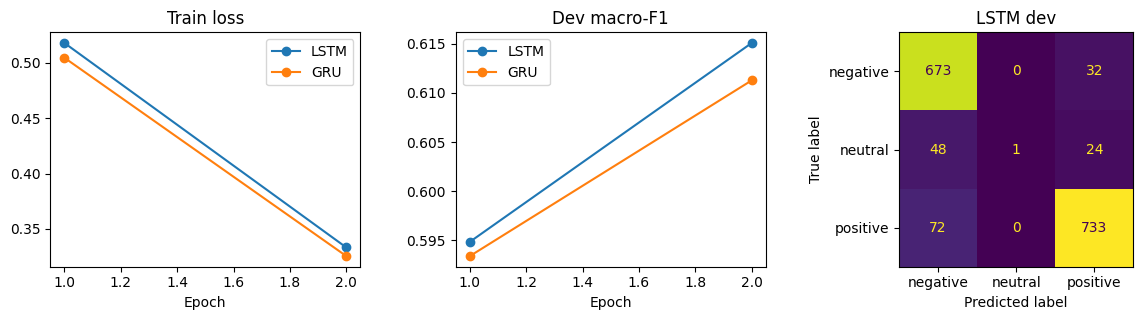

Đã lưu classification.png.


In [40]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.3))
for name, history in [("LSTM", lstm_history), ("GRU", gru_history)]:
    axes[0].plot([r["epoch"] for r in history],
                 [r["loss"] for r in history], marker="o", label=name)
    axes[1].plot([r["epoch"] for r in history],
                 [r["dev_f1"] for r in history], marker="o", label=name)
axes[0].set_title("Train loss")
axes[1].set_title("Dev macro-F1")
for ax in axes[:2]:
    ax.set_xlabel("Epoch")
    ax.legend()
ConfusionMatrixDisplay.from_predictions(
    y_true, y_pred, labels=[0, 1, 2], display_labels=LABELS,
    ax=axes[2], colorbar=False,
)
axes[2].set_title("LSTM dev")
fig.tight_layout()
fig.savefig(ART / "classification.png", dpi=150)
plt.show()
print("Đã lưu classification.png.")

## B.6. BiLSTM và nhận diện thực thể PhoNER

### Phân biệt F1 theo token và theo thực thể

Ví dụ này do người soạn tạo: token Hà Nội có nhãn B-LOCATION, I-LOCATION. Dự đoán chỉ đúng chữ Hà vẫn sai thực thể vì thiếu biên kết thúc. Lab dùng seqeval ở chế độ strict IOB2, tính micro-F1 trên các thực thể; không dùng macro-F1 của bài phân loại câu cho NER.

In [41]:
gold = [["O", "B-LOCATION", "I-LOCATION", "O"]]
guess = [["O", "B-LOCATION", "O", "O"]]
token_accuracy = np.mean(np.array(gold[0]) == np.array(guess[0]))
print("Token accuracy:", token_accuracy)
print("Entity F1:", entity_f1(gold, guess, mode="strict", scheme=IOB2))
print("Ví dụ tự tạo: đúng 3/4 token nhưng đúng 0/1 thực thể.")

Token accuracy: 0.75
Entity F1: 0.0
Ví dụ tự tạo: đúng 3/4 token nhưng đúng 0/1 thực thể.


### Mã hóa PhoNER và bỏ qua nhãn đệm

Xây từ điển và danh sách nhãn từ train PhoNER. PAD_TAG=-100 chỉ dùng để đệm nhãn, không phải lớp dự đoán thứ 22. Không cắt câu trong lab này nhằm giữ trọn biên thực thể; padding động theo câu dài nhất của batch.

In [42]:
ner_vocab = build_vocab(r["words"] for r in ner["train"])
TAGS = sorted({tag for row in ner["train"] for tag in row["tags"]})
tag_to_id = {tag: i for i, tag in enumerate(TAGS)}
PAD_TAG = -100
assert len(TAGS) == 21
assert all(tag in tag_to_id for split in ["dev", "test"]
           for row in ner[split] for tag in row["tags"])

def ner_rows(rows):
    return [(encode(r["words"], ner_vocab),
             [tag_to_id[t] for t in r["tags"]]) for r in rows]

def collate_ner(rows):
    ids = [torch.tensor(x) for x, _ in rows]
    tags = [torch.tensor(y) for _, y in rows]
    lengths = torch.tensor([len(x) for x in ids])
    return (pad_sequence(ids, batch_first=True, padding_value=PAD),
            lengths,
            pad_sequence(tags, batch_first=True,
                         padding_value=PAD_TAG))

ner_train = ner_rows(ner["train"])
ner_dev = ner_rows(ner["dev"])
def ner_loader(rows, shuffle=False):
    return DataLoader(rows, batch_size=cfg["batch"],
                      shuffle=shuffle, collate_fn=collate_ner,
                      generator=torch.Generator().manual_seed(42))

nx, nl, ny = next(iter(ner_loader(ner_train)))
print("Số nhãn BIO:", len(TAGS), "| PAD_TAG:", PAD_TAG)
print("ids/nhãn:", tuple(nx.shape), tuple(ny.shape))
print("Số câu train/dev:", len(ner_train), len(ner_dev))

Số nhãn BIO: 21 | PAD_TAG: -100
ids/nhãn: (32, 117) (32, 117)
Số câu train/dev: 5027 2000


### Cài BiLSTM cho từng token

BiLSTM trả vector 2H tại từng vị trí. pad_packed_sequence khôi phục chiều dài bằng total_length để logits và nhãn đệm luôn cùng shape. Linear(2H, 21) phân loại mỗi token độc lập; đây là BiLSTM thuần, chưa có CRF.

- TODO 4: Ghép hai chiều nên đầu vào Linear có 2H chiều.
- TODO 5: Bỏ qua đúng nhãn đệm -100 khi tính loss.

In [44]:
class TokenTagger(nn.Module):
    def __init__(self, vocab_size, num_tags, emb=64,
                 hidden=64, layers=1, dropout=0.3):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb, padding_idx=PAD)
        self.rnn = nn.LSTM(
            emb, hidden, layers, batch_first=True,
            bidirectional=True,
            dropout=dropout if layers > 1 else 0.0,
        )
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(2 * hidden, num_tags)

    def forward(self, ids, lengths):
        packed = pack_padded_sequence(
            self.emb(ids), lengths.cpu(), batch_first=True,
            enforce_sorted=False,
        )
        output, _ = self.rnn(packed)
        output, _ = pad_packed_sequence(
            output, batch_first=True, total_length=ids.size(1),
        )
        return self.fc(self.drop(output))

seed_all()
tagger = TokenTagger(len(ner_vocab), len(TAGS), **model_args).to(device)
criterion_ner = nn.CrossEntropyLoss(ignore_index=PAD_TAG)
logits = tagger(nx.to(device), nl)
loss = criterion_ner(logits.reshape(-1, len(TAGS)),
                     ny.to(device).reshape(-1))
assert logits.shape[:2] == ny.shape
print("logits:", tuple(logits.shape), "| Loss hữu hạn:",
      bool(torch.isfinite(loss)))


logits: (32, 117, 21) | Loss hữu hạn: True


### Kiểm tra padding của BiLSTM và loss

Kiểm tra cả hai chiều hồi quy: cùng token thật với đệm 8/64 phải cho cùng logits. Thêm nhãn -100 cũng không được làm đổi cross-entropy trung bình. Dùng eval để tắt dropout trước khi đối chiếu.

In [45]:
toy_ids = encode(["Ví", "dụ", "tự", "tạo"], ner_vocab)
def padded_ner(n):
    return torch.tensor([toy_ids + [PAD] * (n - len(toy_ids))],
                         device=device)

tagger.eval()
with torch.no_grad():
    n8 = tagger(padded_ner(8), torch.tensor([4]))
    n64 = tagger(padded_ner(64), torch.tensor([4]))
torch.testing.assert_close(n8[:, :4], n64[:, :4],
                           atol=1e-6, rtol=1e-5)
target = torch.tensor([[tag_to_id["O"]] * 4], device=device)
a = criterion_ner(n8[:, :4].reshape(-1, len(TAGS)), target.flatten())
padded_target = torch.cat([
    target, torch.full((1, 4), PAD_TAG, device=device)], dim=1)
b = criterion_ner(n8.reshape(-1, len(TAGS)), padded_target.flatten())
torch.testing.assert_close(a, b)
print("BiLSTM đệm 8/64: PASS | Loss bỏ padding: PASS")

BiLSTM đệm 8/64: PASS | Loss bỏ padding: PASS


### Huấn luyện và đánh giá BiLSTM bằng seqeval

Chuyển dự đoán về danh sách nhãn chuỗi, cắt theo length thật trước khi chấm. Checkpoint chọn bằng entity-F1 dev. Tại lớp, mạng nhỏ chạy ít epoch để quan sát mô hình bắt đầu học nhãn thực thể; kết quả chỉ kiểm chứng quy trình.

- TODO 6: Cắt nhãn thật theo độ dài, bỏ PAD_TAG trước khi đổi nhãn.
- TODO 7: Chỉ chấm dự đoán tại token thật.

In [48]:
def evaluate_ner(model, loader):
    model.eval()
    true, pred = [], []
    with torch.no_grad():
        for ids, lengths, labels in loader:
            predicted = model(ids.to(device), lengths).argmax(-1).cpu()
            for actual, guessed, length in zip(labels, predicted, lengths):
                n = int(length)
                true.append([TAGS[int(i)] for i in actual[:n]])
                pred.append([TAGS[int(i)] for i in guessed[:n]])
    score = entity_f1(true, pred, mode="strict", scheme=IOB2,
                      zero_division=0)
    return score, true, pred

def fit_ner(model):
    optimizer = torch.optim.Adam(model.parameters(), lr=cfg["lr"])
    best, best_state, history = -1.0, None, []
    for epoch in range(1, cfg["ner_epochs"] + 1):
        model.train()
        start = time.perf_counter()
        total_loss, tokens = 0.0, 0
        for ids, lengths, labels in ner_loader(ner_train, shuffle=True):
            ids, labels = ids.to(device), labels.to(device)
            optimizer.zero_grad(set_to_none=True)
            logits = model(ids, lengths)
            loss = criterion_ner(logits.reshape(-1, len(TAGS)),
                                 labels.reshape(-1))
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            count = int((labels != PAD_TAG).sum())
            total_loss += loss.item() * count
            tokens += count
        seconds = time.perf_counter() - start
        score, _, _ = evaluate_ner(model, ner_loader(ner_dev))
        history.append(dict(epoch=epoch, loss=total_loss/tokens,
                            dev_f1=score, seconds=seconds))
        if score > best:
            best, best_state = score, copy.deepcopy(model.state_dict())
        print(f"BiLSTM epoch {epoch}: loss={total_loss/tokens:.4f} "
              f"dev_entity_F1={score:.4f}")
    model.load_state_dict(best_state)
    model.eval()
    torch.save(best_state, ART / "bilstm_ner.pt")
    return history

ner_history = fit_ner(tagger)
ner_score, ner_true, ner_pred = evaluate_ner(tagger, ner_loader(ner_dev))
print(entity_report(ner_true, ner_pred, mode="strict", scheme=IOB2,
                     digits=4, zero_division=0))


BiLSTM epoch 1: loss=0.4260 dev_entity_F1=0.5867
BiLSTM epoch 2: loss=0.2515 dev_entity_F1=0.7336
BiLSTM epoch 3: loss=0.1789 dev_entity_F1=0.7850
                     precision    recall  f1-score   support

                AGE     0.9041    0.8615    0.8823       361
               DATE     0.9361    0.8640    0.8986      1103
             GENDER     0.9194    0.8231    0.8686       277
                JOB     0.0000    0.0000    0.0000       132
           LOCATION     0.8139    0.7848    0.7991      2737
               NAME     0.0000    0.0000    0.0000       188
       ORGANIZATION     0.7109    0.5445    0.6166       551
         PATIENT_ID     0.8816    0.8582    0.8697      1276
SYMPTOM_AND_DISEASE     0.7092    0.5953    0.6473       766
     TRANSPORTATION     0.6575    0.5517    0.6000        87

          micro avg     0.8349    0.7407    0.7850      7478
          macro avg     0.6533    0.5883    0.6182      7478
       weighted avg     0.7968    0.7407    0.7669      74

## B.7. Checkpoint và quy trình chấm test

### Lưu cấu hình, từ điển và nạp lại checkpoint

Checkpoint cần đi cùng kiến trúc, từ điển, ánh xạ nhãn và nguồn dữ liệu. Nạp state_dict bằng map_location=device để dùng được trên CPU. Kết quả trước và sau khi nạp phải khớp khi mô hình ở eval mode.

In [49]:
metadata = dict(
    config=cfg, seed=42, device=str(device),
    torch_version=str(torch.__version__), vocab=vocab,
    labels=LABELS, ner_vocab=ner_vocab, tags=TAGS,
    files=[dict(path=p, url=u, sha256=h) for p, u, h in DATA_FILES],
    histories=dict(lstm=lstm_history, gru=gru_history, ner=ner_history),
)
(ART / "metadata.json").write_text(
    json.dumps(metadata, ensure_ascii=False, indent=2), encoding="utf-8")
restored = TextClassifier(len(vocab), **model_args).to(device)
restored.load_state_dict(torch.load(ART / "lstm.pt",
                                     map_location=device, weights_only=True))
restored.eval()
ids, lengths, _ = next(iter(dev_loader))
with torch.no_grad():
    torch.testing.assert_close(restored(ids.to(device), lengths),
                               lstm(ids.to(device), lengths))
print("Nạp lại checkpoint LSTM: PASS")
print("Đã lưu metadata.json và ba checkpoint trong", ART)

Nạp lại checkpoint LSTM: PASS
Đã lưu metadata.json và ba checkpoint trong c:\Users\phucp\OneDrive\Desktop\DS201\Lab3\artifacts


### Chấm test một lần sau khi chốt mô hình

Chỉ chạy ô dưới khi đã hoàn tất Phần C với cấu hình của đề và đã chọn checkpoint bằng dev. Không dùng kết quả test để chỉnh siêu tham số; nếu sửa mô hình sau khi xem test thì phải ghi rõ trong báo cáo.

In [50]:
test_loader = cls_loader(cls_rows(vsfc["test"]))
rows = []
for name, model in [("LSTM", lstm), ("GRU", gru)]:
    score, true, pred = evaluate_cls(model, test_loader)
    rows.append(dict(model=name, test_macro_F1=score,
                     test_accuracy=accuracy_score(true, pred)))
    print(name, classification_report(
        true, pred, labels=[0, 1, 2], target_names=LABELS,
        digits=4, zero_division=0))
pred = baseline.predict([r["sentence"] for r in vsfc["test"]])
true = [label_to_id[r["sentiment"]] for r in vsfc["test"]]
rows.append(dict(model="TF-IDF", test_macro_F1=f1_score(
    true, pred, labels=[0, 1, 2], average="macro", zero_division=0),
    test_accuracy=accuracy_score(true, pred)))
pd.DataFrame(rows).to_csv(ART / "classification_test.csv", index=False)
score, true, pred = evaluate_ner(
    tagger, ner_loader(ner_rows(ner["test"])))
report = entity_report(true, pred, mode="strict", scheme=IOB2,
                        digits=4, zero_division=0)
(ART / "ner_test.txt").write_text(report, encoding="utf-8")
print("BiLSTM NER test entity-F1:", round(score, 4))
print(report)

LSTM               precision    recall  f1-score   support

    negative     0.8245    0.9702    0.8914      1409
     neutral     0.0000    0.0000    0.0000       167
    positive     0.9343    0.8855    0.9093      1590

    accuracy                         0.8765      3166
   macro avg     0.5863    0.6186    0.6002      3166
weighted avg     0.8361    0.8765    0.8534      3166

GRU               precision    recall  f1-score   support

    negative     0.8529    0.9503    0.8990      1409
     neutral     0.0000    0.0000    0.0000       167
    positive     0.9084    0.9107    0.9095      1590

    accuracy                         0.8803      3166
   macro avg     0.5871    0.6203    0.6028      3166
weighted avg     0.8358    0.8803    0.8569      3166

BiLSTM NER test entity-F1: 0.7847
                     precision    recall  f1-score   support

                AGE     0.9033    0.8351    0.8679       582
               DATE     0.9365    0.8470    0.8895      1654
           

## Phần C. Bài tập về nhà


### Bài 1. LSTM 5 lớp cho phân loại cảm xúc

**Yêu cầu:** Xây LSTM num_layers=5, hidden_size=256 cho sentiment UIT-VSFC; tối ưu bằng Adam. Dùng packing, chọn epoch theo macro-F1 dev và đánh giá checkpoint đã chọn trên test. Chạy baseline TF-IDF với cùng chia tập để có mốc đối chiếu.

**Dữ liệu:** Toàn bộ UIT-VSFC: 11.426 train, 1.583 dev, 3.166 test. Chỉ dùng sentence làm đầu vào và sentiment làm nhãn; không dùng topic làm đặc trưng.

**Định dạng kết quả:** Bảng accuracy, precision-macro, recall-macro, F1-macro trên test; F1 từng lớp; confusion matrix; đường loss/F1; số tham số và thời gian/epoch. Phân tích ít nhất 3 trường hợp dự đoán sai trên dev.

**Gợi ý:** Giữ layers=5 và hidden=256. Dùng lại TextClassifier và fit_cls; không thêm Softmax trước CrossEntropyLoss.

### Bài 2. GRU 5 lớp và so sánh với LSTM

**Yêu cầu:** Xây GRU num_layers=5, hidden_size=256 trên cùng nhiệm vụ sentiment; dùng Adam. Giữ cấu hình và quy trình đánh giá của Bài 1. Lập bảng so sánh hai mô hình và baseline, giải thích chất lượng cùng chi phí huấn luyện.

**Dữ liệu:** Dùng đúng các tệp train/dev/test, từ điển, cách tách token và ánh xạ sentiment của Bài 1.

**Định dạng kết quả:** Cùng các độ đo của Bài 1, thêm bảng LSTM/GRU với F1-macro, số tham số, thời gian/epoch và epoch tốt nhất trên dev. Không giả định GRU phải thắng hoặc LSTM phải thắng.

**Gợi ý:** TextClassifier(kind='GRU') dùng h_n trực tiếp. Khởi tạo lại seed và mô hình, không tái sử dụng trạng thái optimizer của Bài 1.

### Bài 3. Encoder BiLSTM 5 lớp cho NER

**Yêu cầu:** Xây encoder gồm 5 lớp BiLSTM, hidden_size=256 cho mỗi chiều, nối Linear(512, 21) để gán nhãn BIO. Dùng packing và CrossEntropyLoss(ignore_index=-100). Chọn checkpoint theo entity-F1 dev và chấm test bằng seqeval strict IOB2.

**Dữ liệu:** Toàn bộ PhoNER_COVID19 bản syllable: 5.027 train, 2.000 dev, 3.000 test. Giữ nguyên words/tags; không tách từ lại và không đổi bộ chia tập.

**Định dạng kết quả:** Precision, recall, micro-F1 mức thực thể trên test; F1 từng loại thực thể; số tham số, thời gian/epoch, epoch tốt nhất. Phân tích ít nhất 3 kiểu lỗi trên dev; dùng ví dụ tự tạo khi minh họa trong repo công khai.

**Gợi ý:** Cắt predicted và labels theo length trước khi đổi id sang nhãn chuỗi. Không tính PAD vào F1 và không dùng token accuracy làm kết quả NER chính.

### Bài 4*. Ảnh hưởng của độ sâu hoặc CRF

**Yêu cầu:** Chọn một hướng: (a) so sánh num_layers={1,2,5} của LSTM hoặc GRU ở hidden_size=256, giữ các yếu tố còn lại; (b) bổ sung CRF sau BiLSTM và đối chiếu với Bài 3. Giữ đúng chia tập, quy trình chọn checkpoint và độ đo của bài tương ứng.

**Dữ liệu:** Dữ liệu và tiền xử lý của bài được chọn; không bổ sung dữ liệu ngoài vào phép so sánh chính.

**Định dạng kết quả:** Bảng kết quả, số tham số, thời gian/epoch và giải thích dựa trên số đo. Phân biệt thay đổi kiến trúc với thay đổi số tham số; không suy rộng từ một seed thành kết luận tuyệt đối.

Cấu hình chung cho ba bài bắt buộc: embedding=300, hidden=256, layers=5, dropout=0.3, batch=32, Adam lr=1e-3, clip_grad_norm_=1.0, seed=42, tối đa 10 epoch; giữ checkpoint có F1 dev cao nhất. Embedding được học từ đầu, không thay kiến trúc yêu cầu bằng mô hình pretrained. 